# Tutoriel et expliquation ce la démarche d'optimisation et unittesting

## Tuto

Le readme contient les commandes que l'on peut effectuer dans le terminal. Ici il sera question uniquement des fonctions python directement utilisables.

In [10]:
import sys; sys.path.insert(0, "..")
from benchmark.benchmark import run_benchmark, rapport, tracer

import matplotlib.pyplot as plt

Faire un benchmark et l'afficher. On a pris 2000 comme nnz maximum, et `matCOOPure` est inclu dans le benchmark. 

In [11]:
N = 2000
res = run_benchmark(N, avec_pure=True)
texte = rapport(res)
print(texte)

Produit matrice-vecteur, matrice 2000x2000, nnz variable (temps en s)
     nnz |   coo_pure |  coo_optim |      numpy |      scipy
      50 |   1.50e-05 |   1.94e-06 |   5.74e-03 |   1.03e-05
     100 |   5.04e-05 |   2.99e-06 |   5.28e-03 |   1.04e-05
     200 |   9.74e-05 |   3.47e-06 |   6.12e-03 |   1.05e-05
     500 |   1.41e-03 |   4.54e-06 |   1.24e-03 |   1.06e-05
    1000 |   4.99e-04 |   6.02e-06 |   5.71e-03 |   1.16e-05
    2000 |   9.68e-04 |   9.05e-06 |   1.48e-03 |   1.39e-05

Produit matrice-vecteur, taux de remplissage 0.5%, dimension variable (temps en s)
       n |   coo_pure |  coo_optim |      numpy |      scipy
      20 |   2.48e-06 |   2.30e-06 |   1.76e-06 |   9.06e-06
      50 |   7.22e-06 |   2.32e-06 |   1.97e-06 |   9.10e-06
     100 |   2.55e-05 |   2.48e-06 |   2.92e-06 |   8.77e-06
     200 |   9.58e-05 |   3.17e-06 |   5.56e-06 |   9.01e-06
     500 |   6.15e-04 |   6.66e-06 |   5.43e-05 |   1.08e-05



Sauvegarder les résultats du benchmark dans un fichier texte.

In [12]:
with open("FICHIER", "w", encoding="utf-8") as f:
    f.write(texte)

Afficher et enregistrer les graphes.

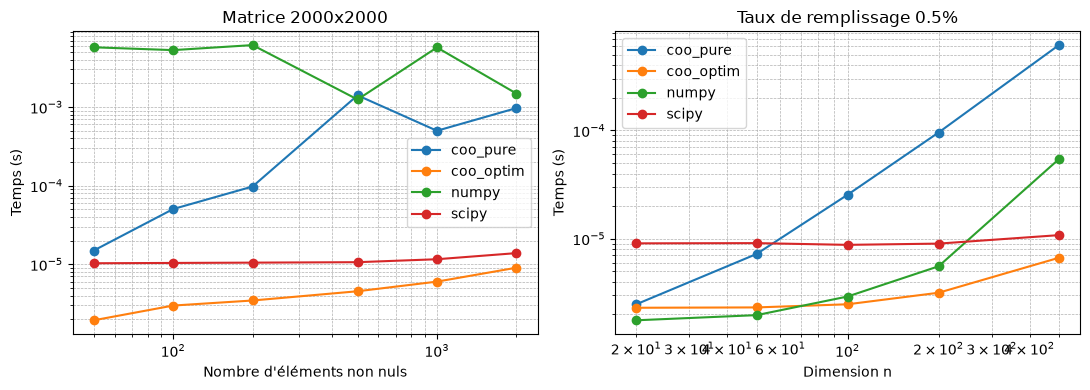

In [13]:
tracer(res, "GRAPHES")
plt.show()

## Contexte

De nombreuses applications nécessitent l'utilisation de matrices de très grande taille, avec par exemple des millions de lignes et de colonnes. C'est notamment le cas en sciences et ingénierie lors de la résolution d'équations aux dérivées partielles (EDPs), par exemple avec la méthode des éléments finis. Par chance, ces très grandes matrices contiennent une large majorité de zéros. C'est ce que l'on appelle des **matrices creuses** (sparse) en anglais.
Ainsi, leur facteur de remplissage est inférieure à 1%. Par exemple, on représente ci-dessous les valeurs non nulles d'une matrice d'éléments finis.
<img src="https://upload.wikimedia.org/wikipedia/commons/8/8a/Finite_element_sparse_matrix.png?uselang=fr" alt="sparse-mat" width="400" height="200">

Puisqu'il y a en fait très peu d'information à stocker, c'est à dire les éléments non nuls de la matrice, on ne va pas utiliser des tableaux numpy de taille (n,m) (dit "plein") mais un format spécifique. Parmis les plus classiques, on va implémenter le format **COO** (coordinate list) qui n'est forcément le plus efficace mais qui présente de bonnes performances. Il se présente de la façon suivante: 
> pour chaque valeur non nulle on stoque le **triplet (ligne, colonne, valeur)**.

**Exemple :**

Considérons la matrice suivante de taille 5x5 :
$$
\begin{pmatrix}
0 & 0 & 0 & 0 & 5 \\
0 & 8 & 0 & 0 & 0 \\
0 & 0 & 0 & 3 & 0 \\
0 & 6 & 0 & 0 & 0 \\
7 & 0 & 0 & 0 & 0
\end{pmatrix}
$$

Comme expliqué plus haut, cette matrice est principalement constituée de zéros, donc il serait inefficace de la stocker dans un tableau plein. Si on utilise le format COO pour stocker uniquement les éléments non nuls, cela donne
$$
\begin{array}{ccc}
(0, 4, 5) \\
(1, 1, 8) \\
(2, 3, 3) \\
(3, 1, 6) \\
(4, 0, 7)
\end{array}
$$


## Opérations de base sur les matrices
Pour que notre format soit utile, il faut pouvoir effectuer les opérations de base sur les matrices. On va donc implémenter les opérations suivantes:
- produit matrice-vecteur
- produit matrice-matrice
- conversion COO vers et depuis le format plein (numpy)

### Produit matrice-vecteur
*Si $A=(a_{ij})$ est une matrice de taille $(m, n)$ et $\mathbf{b}=(b_{i})$ est un vecteur de taille $n$, alors leur produit, noté $A\mathbf{b}=\mathbf{c}^T$ est un vecteur de taille $m$ donnée par :*
$$\forall i: c_{i} = \sum_{k=1}^n a_{ik}b_{k} = a_{i1}b_{1}+a_{i2}b_{2}+\cdots+ a_{in}b_{n}$$

### Produit matrice-matrice
*Si $A=(a_{ij})$ est une matrice de type $(m, n)$ et  $B=(b_{ij})$ est une matrice taille $(n,p)$, alors leur produit, noté $AB=C$ est une matrice de taille $(m,p)$ donnée par :*
$$\forall i<n,\, j<p, \quad C_{ij} = \sum_{k=1}^n a_{ik}b_{kj} = a_{i1}b_{1j}+a_{i2}b_{2j}+\cdots+ a_{in}b_{nj}$$

### Classe(s) matrice COO
Afin de se concentrer sur la performance du code, une implémentation du format COO est fournie dans le fichier `matrice_coo.py`. Vous vous en servirez comme une base pour vos tests et le développement d'une version plus performante.

La classe `MatCooPure` est une représentation d'une matrice au format COO (Coordinate List), utilisant uniquement du python pure (listes et boucles). Voici une description des principales caractéristiques de cette classe :

#### Attributs :
- `n` : Un entier représentant le nombre de lignes de la matrice.
- `m` : Un entier représentant le nombre de colonnes de la matrice.
- `data` : Une liste de tuples contenant les coordonnées `i`,`j` et la `valeur` de chaque élément non nul de la matrice.
- `nnz` : Le nombre d'éléments non nuls dans la matrice (cet attribut est en lecture seule et peut être consulté mais pas modifié).

#### Méthodes :
- `__init__(self, n, m, data=None)`: Le constructeur de la classe permet d'initialiser une matrice COO avec un nombre de lignes `n` et un nombre de colonnes `m`. La liste `data` est optionnelle et permet de fournir des éléments non nuls pour la matrice.

- `fill_random(self, nnz, seed=None)`: Cette méthode remplit la matrice avec des valeurs aléatoires. Vous pouvez spécifier le nombre d'éléments non nuls `nnz` à générer, ainsi qu'une graine `seed` pour le générateur de nombres aléatoires.

- `random(cls, n, m, nnz, seed=None)`: Une méthode de classe qui crée une matrice COO aléatoire de taille `n x m` avec `nnz` éléments non nuls.

- `identity(cls, n)`: Une méthode de classe qui crée une matrice identité de taille `n x n`.

- `from_numpy(cls, data)`: Une méthode de classe qui crée une instance de `MatCooPure` à partir d'un tableau NumPy.

- `to_numpy(self)`: Convertit la matrice COO en un tableau NumPy dense.

- `__str__(self)`: Renvoie une représentation sous forme de chaîne de la matrice COO.

- `__repr_pretty_(self, p, cycle)`: Permet d'afficher la matrice de manière lisible lorsque vous l'utilisez dans IPython.

- `mat_vec_product(self, vec)`: Calcule le produit de la matrice COO par un vecteur.

- `mat_mat_product(self, other)`: Calcule le produit de deux matrices COO.

- `__mul__(self, vec)`: Surcharge l'opérateur `*` pour calculer le produit de la matrice COO par un vecteur ou une autre matrice COO.

- `__matmul__(self, other)`: Surcharge l'opérateur `@` pour la multiplication de matrices.

- `__neg__(self): Surcharge l'opérateur`: `-` pour calculer l'opposé de la matrice COO.

- `__sub__(self, other)`: Surcharge l'opérateur `-` pour calculer la différence entre deux matrices COO. (S'appuie sur `__neg__` et `__add__`.)

## Benchmarker l'implémentation de la matrice COO
Puisque la performance est clé dans le cadre d'utilisation des matrices COO (calcul scientifique, data mining etc), nous allons nous efforcer d'obtenir les meilleurs résultats possibles en termes de vitesse. Même si tous les exemples vus dans le cours instrumentent des fonctions, on ne peut pas faire l'économie d'une structure particulière et donc d'une classe pour ce TP comme dans de nombreux projets.

### Benchmark : comparaison avec numpy.ndarray (plein)
Pour tous les exemples ci-dessous, on comparera l'usage mémoire et le temps de calcul. Vous exécuterez les benchmarks pour les valeurs de n suivantes $n \in \{100,1000,2000\}$. Dans la mesure du possible (temps de calcul inférieur à 1 minute), effectuera les taches ci-dessous pour des arrays `numpy` (adapté aux matrices pleines) puis pour notre format creux COO `MatCooPure`. Enfin vous comparerez ces résultats avec le format creux COO de scipy [`scipy.sparse.coo_matrix`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.coo_matrix.html).
> Attention si un cas s'approche de la minute sur votre machine, n'augmentez plus la taille du problème.

- Soustraire `mat1` à `mat1`, quelle est l'empreinte mémoire? Ajuster votre programme si l'empreinte n'est pas 0.
- Multiplier ces deux matrices entre elles. 
- Multiplier la matrice de taille $n \times n$ avec un vecteur de taille $n$.
- Faire de même pour une matrice creuse avec un taux de remplissage de 1 pour 1000.

### Benchmark : une vrai matrice creuse
Générer une matrice de dimension $10^6 \times 10^8$ avec $10^7$ entrés non nulles et la multiplier avec un vecteur de taille correspondante. Vous proposerez **une évaluation du temps de calcul pertinente et de l'empreinte mémoire**
- d'un point de vue global (timeit, etc.) et vous le comparerez avec la scipy.sparse.coo proposée
- d'un point de vue ligne par ligne (profiler, memory profiler.)

On affichera les résultats de manière graphique avant de les commenter.

> *Les dimensions de matrice proposées ici sont volontairement grandes. N'hésitez pas à ajuster à la baisse si votre machine ne donne pas les résultats en 1min.*


**Initialisation**: on crée une matrice (pleine) aléatoire de taille $n \times n$ `mat1` et une de taille $n \times n/10$ `mat2`.

%load_ext autoreload
%autoreload 2conda a
%load_ext memory_profiler

In [14]:
import numpy as np
from mat_coo_pure import MatCooPure
import scipy.sparse as sp
from utils import *

In [15]:
n=100

In [16]:
# Déclaration des matrices
mat1_NP=np.random.rand(n,n)
mat2_NP=np.random.rand(n,n//10)
mat1_COO=MatCooPure.from_numpy(mat1_NP)
mat2_COO=MatCooPure.from_numpy(mat2_NP)
mat1_COO_scipy=sp.coo_matrix(mat1_NP)
mat2_COO_scipy=sp.coo_matrix(mat2_NP)
mat1_COO.dev_show()
print(type(mat1_COO),type(mat1_COO_scipy))
mat1_COO_scipy.coords
print(type(9)==int)

COO matrix ((100, 100)) with nnz=10000
  0   0   0.6575777150350754
  0   1   0.8065153183955789
...
  99   98   0.034234680455146216
  99   99   0.30540670368007183

Memory footprint: 85176 bytes.
<class 'mat_coo_pure.MatCooPure'> <class 'scipy.sparse._coo.coo_matrix'>
True


In [17]:
mat1_COO.__eq__(mat2_COO)


False

In [18]:
mat1_COO==mat1_COO_scipy

True

#### Soustraire `mat1` à `mat1` pour chaque format
- quel est le temps de calcul?
- quelle est l'empreinte mémoire? 
> Ajuster votre programme si l'empreinte n'est pas 0

In [19]:
%timeit mat1_COO_scipy - mat1_COO_scipy

167 μs ± 5.56 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [20]:
%timeit mat1_COO - mat1_COO

5.77 ms ± 210 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [21]:
%timeit mat1_NP - mat1_NP

2.02 μs ± 54.6 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


#### Multiplication matrice-matrice
Multiplier (au ses mattriciel) `mat1` et `mat2` en reprenant la structure de benchmark suivant pour les format `MatCooPure` et `sp.coo_matrix`. Elle utilise des fonctions et structure de données du module `utils` de ce TP. Complétez le code suivant pour obtenir le plot complet.

La fonction `timer` a été développée spécifiquement pour éviter d'évaluer inutilement des temps de calcul excessifs.
```python
sizes = [20, 50, 100, 200, 500, 1000,2000]
benchmark_results = init_benchmark_results()

# Loop over the sizes
for n in sizes[:]:
    # Create the matrices
    mat1_NP=np.random.rand(n,n)
    mat2_NP=np.random.rand(n,n//10)
    timer( lambda : mat1_NP @ mat2_NP,
            benchmark_results['numpy']['times'],benchmark_results['numpy']['memories'])

    #répliquer les opérations pour les format MatCooPure et sp.coo_matrix
```

In [22]:
sizes = [20, 50, 100, 200, 500, 1000,2000]
benchmark_results = init_benchmark_results()

# Loop over the sizes
for n in sizes[:]:
    # Create the matrices
    mat1_NP=np.random.rand(n,n)
    mat2_NP=np.random.rand(n,n//10)
    mat1_COO = MatCooPure.from_numpy(mat1_NP)
    mat2_COO = MatCooPure.from_numpy(mat2_NP)
    mat1_COO_scipy=sp.coo_matrix(mat1_NP)
    mat2_COO_scipy=sp.coo_matrix(mat2_NP)
    timer(lambda : mat1_NP @ mat2_NP,
            benchmark_results['numpy']['times'])
    timer(lambda: mat1_COO @ mat2_COO,
          benchmark_results['coo']['times'])
    timer(lambda: mat1_COO_scipy @ mat2_COO_scipy,
          benchmark_results['scipy']['times'])

In [23]:
print_benchmark_results(benchmark_results, sizes, show_memory_usage=False)

Matrix Size | COO Pure Time | Numpy Time | Scipy Time
------------|---------------|------------|-----------
     20     |    0.0006     |   0.0000   |  0.0001   
     50     |    0.0198     |   0.0000   |  0.0001   
    100     |    0.2739     |   0.0000   |  0.0003   
    200     |    4.1112     |   0.0000   |  0.0017   
    500     |      nan      |   0.0027   |  0.0282   
    1000    |      nan      |   0.0010   |  0.1270   
    2000    |      nan      |   0.0123   |  0.8867   


On a des nan à partir de 200 car pour cet appel on a dépassé la seconde, c'est le comportement voulu. On voit sur le graphique que notre implémentation matCOOPure est bien moins performante que numpy et matcoo par sparse, et que pour les matrices pleines numpy est plus performant de toute façon.

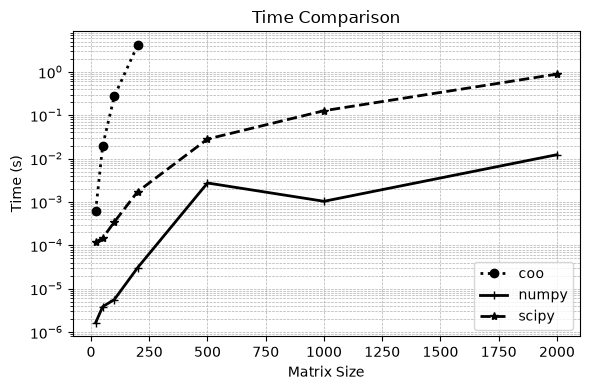

In [24]:
plot_CPU_time_benchmark(sizes, benchmark_results, title='Time Comparison', xlabel='Matrix Size', ylabel='Time (s)')

#### Multiplication matrice pleine - vecteur
Faire de même pour le calcul matrice pleine - vecteur. Comment interpréter les résultats?

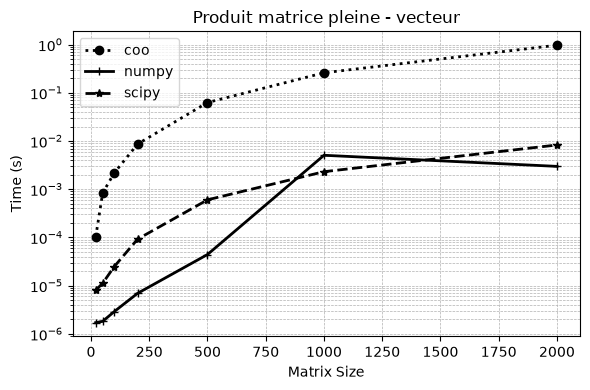

In [25]:
sizes = [20, 50, 100, 200, 500, 1000, 2000]
res_dense = init_benchmark_results()

for n in sizes:
    A_NP = np.random.rand(n, n)
    v = np.random.rand(n)
    A_COO = MatCooPure.from_numpy(A_NP)
    A_SP = sp.coo_matrix(A_NP)
    timer(lambda: A_NP @ v, res_dense['numpy']['times'])
    timer(lambda: A_COO.mat_vec_product(v), res_dense['coo']['times'])
    timer(lambda: A_SP @ v, res_dense['scipy']['times'])

plot_CPU_time_benchmark(sizes, res_dense, title='Produit matrice pleine - vecteur')


Le coût est proportionnel au nombre d'entrées stockées, soit n² pour une matrice pleine : les trois courbes suivent la même pente, doubler n multiplie le temps par environ 4. Ce qui change est le coût par entrée. Le COO pur est plusieurs ordres de grandeur plus lent que numpy (boucle interprétée, objets Python, aucun calcul vectorisé). scipy.coo reste nettement plus lent que numpy sur une matrice pleine, et nettement plus rapide que le COO pur.

#### Multiplication matrice creuse 1/1000 - vecteur
Faire de même pour le calcul matrice creuse avec un taux de remplissage à 1/1000 multipliant un vecteur et donner une interprétation.
Quelles sont les différences manifestes?

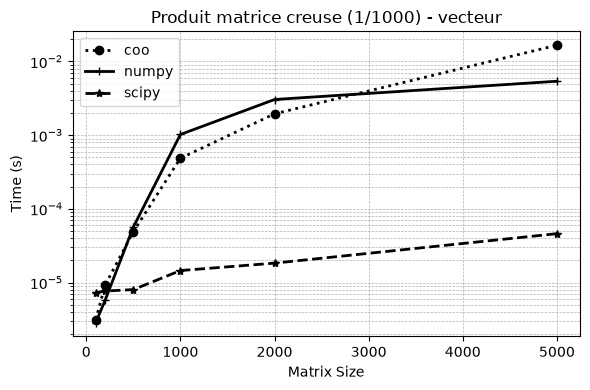

In [26]:
def matrice_creuse(n):
    """Même matrice aléatoire n x n (taux de remplissage 1/1000) dans les trois formats."""
    A_COO = MatCooPure.random(n, n, n * n // 1000, seed=0)
    rows, cols, vals = zip(*A_COO.data)
    A_SP = sp.coo_matrix((vals, (rows, cols)), shape=(n, n))
    return A_COO.to_numpy(), A_COO, A_SP

sizes_sp = [100, 200, 500, 1000, 2000, 5000]
res_sparse = init_benchmark_results()

for n in sizes_sp:
    A_NP, A_COO, A_SP = matrice_creuse(n)
    v = np.random.rand(n)
    timer(lambda: A_NP @ v, res_sparse['numpy']['times'])
    timer(lambda: A_COO.mat_vec_product(v), res_sparse['coo']['times'])
    timer(lambda: A_SP @ v, res_sparse['scipy']['times'])


plot_CPU_time_benchmark(sizes_sp, res_sparse, title='Produit matrice creuse (1/1000) - vecteur')


Les formats COO ne parcourent que les nnz = n²/1000 entrées non nulles, alors que numpy multiplie aussi tous les zéros (n² opérations). L'écart avec numpy se réduit puis s'inverse : à partir de quelques centaines à un millier de lignes, le COO pur, pourtant écrit en boucle Python, passe devant numpy.

### Benchmark : une vrai matrice creuse
Générer une matrice de dimension $10^6 \times 10^8$ avec $10^5$ entrés non nulles et la multiplier avec un vecteur de taille correspondante. 

Proposez **une évaluation du temps de calcul pertinente et de l'empreinte mémoire** en utilisant les **outils vus en cours**:
- d'un point de vue global (timeit, etc.) et vous le comparerez avec la scipy.sparse.coo proposée
- d'un point de vue ligne par ligne (profiler, memory profiler.)

In [29]:
%load_ext line_profiler

The line_profiler extension is already loaded. To reload it, use:
  %reload_ext line_profiler


In [30]:
n, m, nnz = 10**6, 10**8, 10**5
A_COO = MatCooPure.random(n, m, nnz, seed=0)
rows, cols, vals = zip(*A_COO.data)
A_SP = sp.coo_matrix((vals, (rows, cols)), shape=(n, m))
v = np.random.rand(m)  # 10^8 flottants : environ 800 Mo


In [31]:
t_coo = %timeit -o A_COO.mat_vec_product(v)
t_sp = %timeit -o A_SP @ v

397 ms ± 153 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
973 μs ± 50.3 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [32]:
lp = %lprun -r -f MatCooPure.mat_vec_product A_COO.mat_vec_product(v)
lp.print_stats()

Timer unit: 1e-09 s

Total time: 0.309045 s
File: /home/bombastus/Documents/INFOIA/PAPY/benchmark/benchmark/mat_coo_pure.py
Function: MatCooPure.mat_vec_product at line 233

Line #      Hits         Time  Per Hit   % Time  Line Contents
   233                                               def mat_vec_product(self, vec: np.ndarray) -> np.ndarray:
   234                                                   """
   235                                                   Calculate the product of the COO matrix and a vector.
   236                                           
   237                                                   Parameters:
   238                                                   ----------
   239                                                   vec : numpy.ndarray
   240                                                       The vector to multiply with the matrix.
   241                                           
   242                                                   Returns:

Timer unit: 1e-09 s

Total time: 0.309045 s
File: /home/bombastus/Documents/INFOIA/PAPY/benchmark/benchmark/mat_coo_pure.py
Function: MatCooPure.mat_vec_product at line 233

Line #      Hits         Time  Per Hit   % Time  Line Contents
   233                                               def mat_vec_product(self, vec: np.ndarray) -> np.ndarray:
   234                                                   """
   235                                                   Calculate the product of the COO matrix and a vector.
   236                                           
   237                                                   Parameters:
   238                                                   ----------
   239                                                   vec : numpy.ndarray
   240                                                       The vector to multiply with the matrix.
   241                                           
   242                                                   Returns:

scipy est environ deux ordres de grandeur plus rapide que le COO pur.
%lprun montre que `vec=np.array(vec)` pèse autant ou plus en temps que la boucle, car elle copie 10⁸ éléments alors que la boucle n'en traite que 10⁵. Le reste du temps est dans le corps de la boucle (`res[i] += val * vec[j]`) ; les accès à `vec[j]` sont dispersés dans un tableau de 800 Mo, ce qui est probablement défavorable au cache (non mesuré ici). Donc deux choses à améliorer, la conversion en array et la boucle (numpy?)


## Exercice 3 : Optimisation
Fort de vos observation et de vos connaissances, vous aller creer une version beaucoup plus efficace pour traiter des matrices creuses au format COO. 

Nous avons a présent deux chemins à explorer pour améliorer notre programe:
1. **Accélérer l'exécution des boucles** par tous les moyens (amélioration algorithmique, supprimer les boucles, just in time,...)
2. **Créer une classe `MatCooNumpy`**. En effet, nous avons vu que pour les objets tabulaires, les structures de bases qui permettent des calculs rapides en python sont les tableaux `numpy`. Elle aura les mêmes fonctions que `MatCooPure`. Ainsi vous pourrez comparer directement le benchmark écrit plus haut.

> Vos résultats devraient etre comparable avec l'implémentation de scipy.sparse.coo_matrix.

### Accélération du calcul mat-vec creux 

*Dans cette section, on cherche à évaluer les points les plus couteux du calcul du produit matrice vecteur pour le format creux développé ci-dessus. Proposer des amélioration et en mesurer l'effet. Donner ses conclusions motivées par des `%timeit` et des `%lprun`.* 

In [33]:
large_mat, vec = A_COO, v
%timeit large_mat.mat_vec_product(vec)

195 ms ± 13.6 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [34]:
def mat_vec_v1(self, vec):
    """Version 1 : même boucle, sans copie inutile du vecteur."""
    vec = np.asarray(vec)
    if self.m != vec.size:
        raise ValueError(f"Number of columns m={self.m} does not match size of vector {vec.size}")
    res = np.zeros(self.n)
    for i, j, val in self.data:
        res[i] += val * vec[j]
    return res

MatCooPure.mat_vec_v1 = mat_vec_v1  # ajout à la classe depuis le notebook, sans toucher mat_coo_pure.py
%timeit large_mat.mat_vec_v1(vec)

49.1 ms ± 245 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [35]:
def mat_vec_product_optim(self, vec):
    """Version 2 : plus de boucle Python, calcul vectorisé avec numpy."""
    vec = np.asarray(vec)
    if self.m != vec.size:
        raise ValueError(f"Number of columns m={self.m} does not match size of vector {vec.size}")
    if self.nnz == 0:
        return np.zeros(self.n)
    row, col, val = np.array(self.data).T  # liste de tuples -> tableaux
    return np.bincount(row.astype(int), weights=val * vec[col.astype(int)], minlength=self.n)

MatCooPure.mat_vec_product_optim = mat_vec_product_optim
%timeit large_mat.mat_vec_product_optim(vec)

52.2 ms ± 1.04 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [36]:
lp = %lprun -r -f MatCooPure.mat_vec_v1 large_mat.mat_vec_v1(vec)
lp.print_stats()
lp = %lprun -r -f MatCooPure.mat_vec_product_optim large_mat.mat_vec_product_optim(vec)
lp.print_stats()

Timer unit: 1e-09 s

Total time: 0.0958507 s
File: /tmp/ipykernel_75678/3587993341.py
Function: mat_vec_v1 at line 1

Line #      Hits         Time  Per Hit   % Time  Line Contents
     1                                           def mat_vec_v1(self, vec):
     2                                               """Version 1 : même boucle, sans copie inutile du vecteur."""
     3         1       7181.0   7181.0      0.0      vec = np.asarray(vec)
     4         1       2395.0   2395.0      0.0      if self.m != vec.size:
     5                                                   raise ValueError(f"Number of columns m={self.m} does not match size of vector {vec.size}")
     6         1     267733.0 267733.0      0.3      res = np.zeros(self.n)
     7    100001   36750909.0    367.5     38.3      for i, j, val in self.data:
     8    100000   58821836.0    588.2     61.4          res[i] += val * vec[j]
     9         1        603.0    603.0      0.0      return res

Timer unit: 1e-09 s

Total 

Timer unit: 1e-09 s

Total time: 0.050425 s
File: /tmp/ipykernel_75678/3189600392.py
Function: mat_vec_product_optim at line 1

Line #      Hits         Time  Per Hit   % Time  Line Contents
     1                                           def mat_vec_product_optim(self, vec):
     2                                               """Version 2 : plus de boucle Python, calcul vectorisé avec numpy."""
     3         1       1688.0   1688.0      0.0      vec = np.asarray(vec)
     4         1       1375.0   1375.0      0.0      if self.m != vec.size:
     5                                                   raise ValueError(f"Number of columns m={self.m} does not match size of vector {vec.size}")
     6         1       2617.0   2617.0      0.0      if self.nnz == 0:
     7                                                   return np.zeros(self.n)
     8         1   48220555.0 4.82e+07     95.6      row, col, val = np.array(self.data).T  # liste de tuples -> tableaux
     9         1    219876

In [37]:
%timeit large_mat.mat_vec_product_optim(vec)

52.2 ms ± 1.18 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
